# Trial-level model with tremor dominance as a continuous moderator

Continuous counterpart of `notebooks/2.25-posterior-interaction-with-mcmc` (one model per subtype)
and `notebooks/2.27-subtype-comparison` (joint model with a subtype x colour x medication term).
Instead of fitting the subtypes separately or contrasting them, one model is fit to all 22 patients
with an OFF-medication score, and the colour x medication interaction is allowed to vary linearly
with the score:

```
choice ~ score * (signed coherence + colour * medication + previous rewarded choice * medication)
```

- `score` is `score_z`, the standardised log2(tremor / bradykinesia) ratio from the OFF exam
  (`1.10-tremor-brady-score`). The mean patient has score 0, so `col:med` is the medication effect on
  prior use **at the average patient**.
- **`score:col:med` is the coefficient of interest**: how much the medication effect on prior use
  changes per SD of tremor dominance. It is the continuous version of `sub:col:med` in `2.27`.
- Priors, random-effects structure, parameterisation and sampler settings are exactly those of the
  reported fits (`mcmc_cache.FIT_SETTINGS`). Random intercept and slopes by participant on the seven
  within-participant terms; the score is between-participant, so its terms get no random slope.

Checks: alternative forms of the score (rank-based, and tremor and bradykinesia entered separately),
and leave-one-participant-out refits.

Fits are cached under `outputs/notebooks_2/mcmc_cache/`. First run: about 4 minutes per fit plus
about 15 minutes for the leave-one-out refits (22 in parallel, one core each). Nothing is written to the data directory.

In [1]:
%matplotlib inline
%reload_ext autoreload
%autoreload 2
from imports import *

In [2]:
from config import dir_config
from src.utils.mcmc_cache import CACHE_DIR as REPORTED_CACHE_DIR
from src.utils.mcmc_cache import TERMS, prepare_trials
from src.utils.motor_score import OUTPUT_DIR, SCORE, describe, fit_or_load, loso_or_load, motor_scores, standardise

processed_dir = Path(dir_config.data.processed)
filtered_data = pd.read_csv(processed_dir / "processed_all_data_accu_60_filtered.csv", index_col=None)
metadata = pd.read_csv(processed_dir / "processed_metadata_all_data_accu_60.csv", encoding="latin1")
assert not str(OUTPUT_DIR).startswith(str(processed_dir.parents[0])), "never write to the data dir"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

scores = motor_scores(metadata)
trials = prepare_trials(filtered_data, scores.index)
SCORE_SD = scores[SCORE].std(ddof=0)  # log2 units per SD of score_z
CATEGORY_COLOR = {"tremor": "#B5541D", "bradykinetic": "#4A5A6B", "intermediate": "#9A9A9A"}
POSTERIOR_COLOR = "#B5541D"
print(f"{trials['subject_id'].nunique()} participants, {len(trials):,} trials; 1 SD of the score = {SCORE_SD:.2f} log2 units "
      f"(a {2 ** SCORE_SD:.1f}-fold change in the tremor/bradykinesia ratio)")

22 participants, 27,310 trials; 1 SD of the score = 1.41 log2 units (a 2.7-fold change in the tremor/bradykinesia ratio)


## Fit

In [3]:
fit = fit_or_load("score_moderated", trials, {"score": scores["score_z"]})
diag = fit.diagnostics()
print(f"divergences: {fit.divergences}   max r_hat: {diag['r_hat'].max():.4f}   min bulk ESS: {diag['ess_bulk'].min():.0f} ({diag['ess_bulk'].idxmin()})")
diag.round(4)

score_moderated: loaded cached draws (seed 0, fingerprint 7d2928d58ec6fecb)
divergences: 0   max r_hat: 1.0091   min bulk ESS: 395 (coh)


,r_hat,ess_bulk
intercept,1.0041,674.0065
coh,1.0032,395.2066
col,1.0013,821.3497
med,1.0035,767.1619
col:med,1.0019,761.7018
prev_rc,1.0009,940.2528
prev_rc:med,1.0007,1451.6498
score,1.0019,834.7393
score:coh,1.0077,632.4682
score:col,1.0019,1045.7108


## Population-level posterior

In [4]:
posterior_summary = pd.DataFrame({name: describe(fit.term(name)) for name in fit.names}).T
posterior_summary.round(3)

,mean,SD,2.5%,97.5%,P(> 0)
intercept,0.046,0.062,-0.073,0.167,0.779
coh,3.425,0.335,2.784,4.109,1.000
col,0.287,0.084,0.121,0.456,1.000
med,-0.107,0.107,-0.307,0.108,0.159
col:med,0.203,0.212,-0.202,0.627,0.834
prev_rc,0.198,0.045,0.108,0.289,1.000
prev_rc:med,-0.055,0.060,-0.176,0.061,0.174
score,-0.015,0.062,-0.135,0.108,0.405
score:coh,0.183,0.347,-0.506,0.866,0.705
score:col,0.001,0.086,-0.173,0.172,0.509


In [5]:
moderation = fit.term("score:col:med")
per_doubling = moderation / SCORE_SD
print("score:col:med, change in the colour x medication effect (log-odds)")
print(f"  per SD of the score:            {moderation.mean():+.3f}  95% CI [{np.percentile(moderation, 2.5):+.3f}, {np.percentile(moderation, 97.5):+.3f}]  P(> 0) = {(moderation > 0).mean():.3f}")
print(f"  per doubling of the ratio:      {per_doubling.mean():+.3f}  95% CI [{np.percentile(per_doubling, 2.5):+.3f}, {np.percentile(per_doubling, 97.5):+.3f}]")
average = fit.term("col:med")
print(f"col:med at the average patient: {average.mean():+.3f}  95% CI [{np.percentile(average, 2.5):+.3f}, {np.percentile(average, 97.5):+.3f}]  P(> 0) = {(average > 0).mean():.3f}")

score:col:med, change in the colour x medication effect (log-odds)
  per SD of the score:            +0.112  95% CI [-0.343, +0.546]  P(> 0) = 0.712
  per doubling of the ratio:      +0.080  95% CI [-0.244, +0.389]
col:med at the average patient: +0.203  95% CI [-0.202, +0.627]  P(> 0) = 0.834


## Figure. Medication effect on prior use across the tremor-bradykinesia axis

The line and band are the model's colour x medication effect as a function of the score,
`col:med + score:col:med * score_z`, posterior mean and 95% interval. Points are each participant's
own effect (population line plus their random deviation), posterior mean and 95% interval.

The two squares are the separately fitted subtype estimates reported in `notebooks/2.25` (read from
that notebook's cache, read only), placed at the mean score of each subtype, for comparison.

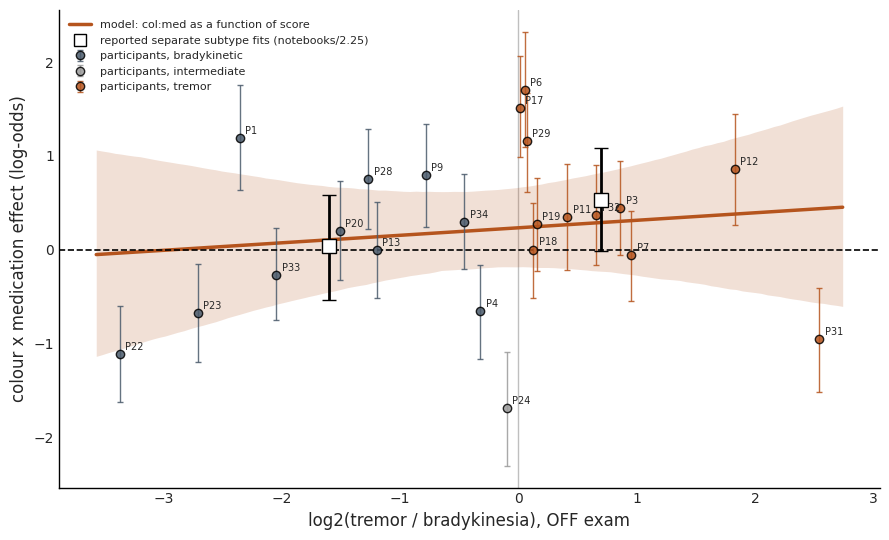

In [6]:
grid = np.linspace(scores[SCORE].min() - 0.2, scores[SCORE].max() + 0.2, 120)
grid_z = (grid - scores[SCORE].mean()) / SCORE_SD
curve = fit.term("col:med")[:, None] + fit.term("score:col:med")[:, None] * grid_z[None, :]

z_by_participant = scores["score_z"].reindex(fit.participants).to_numpy()
participant_draws = fit.term("col:med")[:, None] + fit.term("score:col:med")[:, None] * z_by_participant[None, :] + fit.deviation("col:med")
participant_effects = pd.DataFrame({
    "score": scores[SCORE].reindex(fit.participants).to_numpy(),
    "category": scores["category"].reindex(fit.participants).to_numpy(),
    "mean": participant_draws.mean(0),
    "2.5%": np.percentile(participant_draws, 2.5, axis=0),
    "97.5%": np.percentile(participant_draws, 97.5, axis=0),
}, index=pd.Index(fit.participants, name="participant_id"))

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.fill_between(grid, *np.percentile(curve, [2.5, 97.5], axis=0), color=POSTERIOR_COLOR, alpha=0.18, lw=0)
ax.plot(grid, curve.mean(0), color=POSTERIOR_COLOR, lw=2.5, label="model: col:med as a function of score")
for category, block in participant_effects.groupby("category"):
    ax.errorbar(block["score"], block["mean"], yerr=[block["mean"] - block["2.5%"], block["97.5%"] - block["mean"]],
                ls="", marker="o", ms=6, mec="k", color=CATEGORY_COLOR[category], ecolor=CATEGORY_COLOR[category], alpha=0.85, capsize=2, lw=1, label=f"participants, {category}")
for participant, row in participant_effects.iterrows():
    ax.annotate(participant, (row["score"], row["mean"]), xytext=(4, 3), textcoords="offset points", fontsize=7)

for cached_name, category in [("tremor", "tremor"), ("bradykinetic", "bradykinetic")]:
    path = REPORTED_CACHE_DIR / f"{cached_name}.npz"
    if path.exists():
        with np.load(path) as cached:  # read only
            reported = cached["beta"].reshape(-1, len(TERMS))[:, TERMS.index("col:med")]
        x = scores.loc[scores["category"] == category, SCORE].mean()
        ax.errorbar(x, reported.mean(), yerr=[[reported.mean() - np.percentile(reported, 2.5)], [np.percentile(reported, 97.5) - reported.mean()]],
                    marker="s", ms=10, color="white", mec="k", ecolor="k", capsize=5, lw=2, zorder=5)
ax.plot([], [], "s", color="white", mec="k", ms=9, label="reported separate subtype fits (notebooks/2.25)")

ax.axhline(0, color="k", ls="--", lw=1.2)
ax.axvline(0, color="0.75", lw=1, zorder=0)
ax.set_xlabel("log2(tremor / bradykinesia), OFF exam", fontsize=12)
ax.set_ylabel("colour x medication effect (log-odds)", fontsize=12)
ax.tick_params(labelsize=10)
ax.legend(frameon=False, fontsize=8, loc="upper left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "score_moderated_effect.pdf", bbox_inches="tight")
fig.savefig(OUTPUT_DIR / "score_moderated_effect.png", dpi=200, bbox_inches="tight")
plt.show()

## Does the form of the score matter?

| Variant | Moderators | Why |
|---|---|---|
| Primary | standardised log2 ratio | as above |
| Rank-based | normal scores of the ratio's ranks | removes leverage from the extremes (P31, P12, P22) |
| Components | tremor and bradykinesia severity, each standardised, entered together | a ratio can move because of either component; this separates them |

Each is a separate fit of the same model with different moderator columns.

In [7]:
ranks = stats.rankdata(scores[SCORE])
variants = {
    "primary (log2 ratio)": {"score": scores["score_z"]},
    "rank-based score": {"score": pd.Series(standardise(stats.norm.ppf((ranks - 0.375) / (len(ranks) + 0.25))), index=scores.index)},
    "components": {"tremor": pd.Series(standardise(scores["tremor_score"]), index=scores.index),
                   "brady": pd.Series(standardise(scores["bradykinesia_score"]), index=scores.index)},
}
cache_names = {"primary (log2 ratio)": "score_moderated", "rank-based score": "score_moderated_rank", "components": "score_moderated_components"}

variant_fits = {label: (fit if label.startswith("primary") else fit_or_load(cache_names[label], trials, moderators)) for label, moderators in variants.items()}

variant_rows = []
for label, variant in variant_fits.items():
    vdiag = variant.diagnostics()
    for moderator in variants[label]:
        term = f"{moderator}:col:med"
        variant_rows.append({"variant": label, "term": term, **describe(variant.term(term)),
                             "col:med (average patient)": variant.term("col:med").mean(),
                             "divergences": variant.divergences, "max r_hat": vdiag["r_hat"].max()})
variant_table = pd.DataFrame(variant_rows).set_index(["variant", "term"])
variant_table.round(3)

score_moderated_rank: loaded cached draws (seed 0, fingerprint 169e74d2ff64b02c)
score_moderated_components: loaded cached draws (seed 0, fingerprint 2dd8a37637138f80)


mean     SD   2.5%  97.5%  P(> 0)  \
variant              term                                                 
primary (log2 ratio) score:col:med   0.112  0.220 -0.343  0.546   0.712   
rank-based score     score:col:med   0.105  0.214 -0.327  0.512   0.701   
components           tremor:col:med  0.299  0.206 -0.084  0.710   0.930   
                     brady:col:med   0.098  0.205 -0.298  0.493   0.684   

                                     col:med (average patient)  divergences  \
variant              term                                                     
primary (log2 ratio) score:col:med                       0.203            0   
rank-based score     score:col:med                       0.196            0   
components           tremor:col:med                      0.202            0   
                     brady:col:med                       0.202            0   

                                     max r_hat  
variant              term                       
primary (log2 ratio) score:col:med       1.009  
rank-based score     score:col:med       1.010  
components           tremor:col:med      1.006  
                     brady:col:med       1.006

## Leave-one-participant-out

The score is held at its full-sample standardisation, so every refit's `score:col:med` is in the same
units. As in `notebooks/2.25`, refits use 500 draws per chain (`LOSO_SETTINGS`).

In [8]:
loso = loso_or_load("score_moderated", trials, {"score": scores["score_z"]}, terms=["score:col:med", "col:med"], workers=22)
loso = loso.set_index("held_out").sort_values("score:col:med mean")
print(f"full fit: {moderation.mean():+.3f}; refits range {loso['score:col:med mean'].min():+.3f} to {loso['score:col:med mean'].max():+.3f}; "
      f"same sign in {int((np.sign(loso['score:col:med mean']) == np.sign(moderation.mean())).sum())} of {len(loso)}; "
      f"P(> 0) range {loso['score:col:med P(> 0)'].min():.2f} to {loso['score:col:med P(> 0)'].max():.2f}; "
      f"divergences {int(loso['divergences'].sum())}")
loso[["score:col:med mean", "score:col:med 2.5%", "score:col:med 97.5%", "score:col:med P(> 0)", "col:med mean", "divergences"]].round(3)

score_moderated: loaded cached leave-one-out refits
full fit: +0.112; refits range -0.031 to +0.280; same sign in 21 of 22; P(> 0) range 0.45 to 0.90; divergences 0


,score:col:med mean,score:col:med 2.5%,score:col:med 97.5%,score:col:med P(> 0),col:med mean,divergences
held_out,,,,,,
P22,-0.031,-0.464,0.394,0.446,0.260,0
P23,0.032,-0.442,0.484,0.565,0.243,0
P29,0.075,-0.339,0.468,0.649,0.163,0
P12,0.076,-0.387,0.534,0.634,0.190,0
P17,0.083,-0.318,0.471,0.674,0.113,0
P33,0.087,-0.350,0.520,0.654,0.190,0
P6,0.090,-0.311,0.483,0.684,0.126,0
P20,0.097,-0.343,0.520,0.687,0.182,0
P11,0.098,-0.314,0.517,0.686,0.201,0


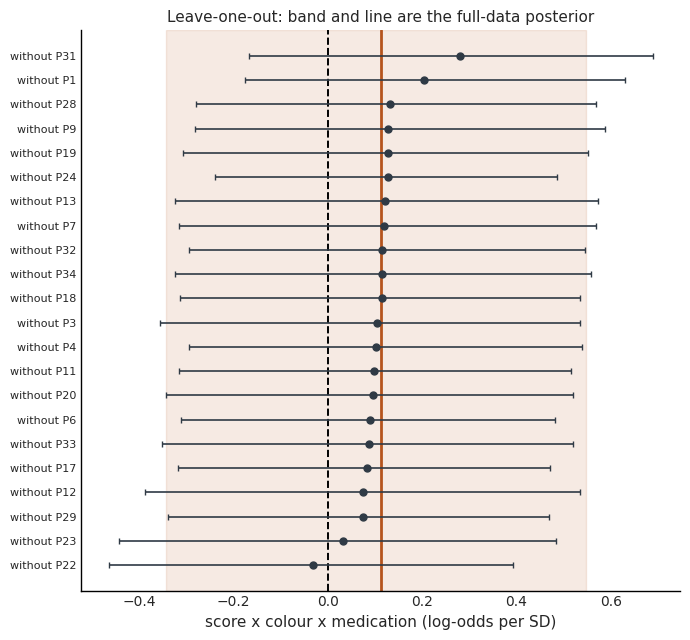

In [9]:
fig, ax = plt.subplots(figsize=(7, 6.5))
positions = np.arange(len(loso))
ax.axvspan(*np.percentile(moderation, [2.5, 97.5]), color=POSTERIOR_COLOR, alpha=0.12, zorder=0)
ax.axvline(moderation.mean(), color=POSTERIOR_COLOR, lw=2)
ax.axvline(0, color="k", ls="--", lw=1.4)
ax.errorbar(loso["score:col:med mean"], positions,
            xerr=[loso["score:col:med mean"] - loso["score:col:med 2.5%"], loso["score:col:med 97.5%"] - loso["score:col:med mean"]],
            ls="", marker="o", ms=5, color="#2F3A45", capsize=2, lw=1.2)
ax.set_yticks(positions)
ax.set_yticklabels([f"without {p}" for p in loso.index], fontsize=8)
ax.set_xlabel("score x colour x medication (log-odds per SD)", fontsize=11)
ax.tick_params(axis="x", labelsize=10)
ax.set_title("Leave-one-out: band and line are the full-data posterior", fontsize=11)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(OUTPUT_DIR / "score_moderated_loso.png", dpi=200, bbox_inches="tight")
plt.show()

In [10]:
posterior_summary.to_csv(OUTPUT_DIR / "score_moderated_posterior.csv")
participant_effects.to_csv(OUTPUT_DIR / "score_moderated_participant_effects.csv")
variant_table.to_csv(OUTPUT_DIR / "score_moderated_variants.csv")
print("wrote score_moderated_* tables and figures to", OUTPUT_DIR.relative_to(OUTPUT_DIR.parents[1]))

wrote score_moderated_* tables and figures to outputs/notebooks_2


## Results and interpretation

Values are from this run. Fits are cached under fixed seeds, so reruns reproduce them.

| | estimate | 95% interval | P(> 0) |
|---|---|---|---|
| **score x colour x medication, per SD of the score** | **+0.11** | **-0.34 to +0.55** | **0.71** |
| same, per doubling of the tremor/bradykinesia ratio | +0.08 | -0.24 to +0.39 | |
| colour x medication at the average patient | +0.20 | -0.20 to +0.63 | 0.83 |
| rank-based score x colour x medication | +0.11 | -0.33 to +0.51 | 0.70 |
| tremor severity x colour x medication (components model) | +0.30 | -0.08 to +0.71 | 0.93 |
| bradykinesia severity x colour x medication (components model) | +0.10 | -0.30 to +0.49 | 0.68 |

Diagnostics: 0 divergences in every fit, max R-hat 1.010, min bulk ESS about 400.

**The medication effect on prior use is not shown to depend on tremor dominance.** The slope is
positive (the direction of the subtype result) but small relative to its uncertainty: 71% posterior
probability of a positive slope, against 90% for the subtype contrast in `notebooks/2.27`. Across
the observed range of the score (about 4 SD), the fitted line rises by only about 0.5 log-odds,
well inside the spread of individual patients.

**The figure shows why.** The two subtype estimates from `notebooks/2.25` sit on or near the fitted
line, so the continuous model does not contradict them. But the patients around them do not form a
gradient. The strongest positive effects (P6, P17, P29) are just above the ratio-1 cut-off. The most
tremor-dominant patient (P31) and the patient just below the cut-off (P24, excluded from the split)
both have clearly negative effects. Bradykinesia-dominant patients range from -1.1 (P22) to +1.2 (P1).

**Not driven by the extremes.** The rank-based score gives the same answer as the log ratio, so
P31's, P12's and P22's leverage is not what keeps the slope small.

**Leave-one-out.** The slope keeps its sign in 21 of 22 refits (means -0.03 to +0.28), P(> 0) between
0.45 and 0.90, and no refit's interval excludes zero. Dropping P22 or P23 (the most bradykinetic, both
negative) flattens it most; dropping P31 steepens it most.

**The components model is the one lead.** Tremor severity alone moderates the medication effect more
than the ratio does (P(> 0) = 0.93), and bradykinesia severity carries the same sign. That points, if
anywhere, at overall symptom severity or tremor severity rather than at the balance between tremor and
bradykinesia, the quantity the subtype was meant to capture. It is one of several secondary checks and
its interval includes zero.

### Reporting

Report the score x colour x medication slope as the test of whether the medication effect on prior
use depends on motor phenotype. Describe the result as a positive slope that the data do not
establish, and note that it is weaker than the subtype contrast because patients near the subtype
cut-off, and at the tremor-dominant extreme, do not follow a gradient.